<a href="https://colab.research.google.com/github/PauloSBLima/vision-auto-check/blob/main/train_mix.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

---
INÍCIO

## 👓 Sobre
## Projeto: <font size="10">🚗</font> <font color="orange">**VisionAutoCheck (VAC)**</font>
## &emsp;&emsp;&emsp;&emsp;&emsp;&nbsp;&nbsp;&nbsp; Sistema Inteligente de Detecção para Oficina Automotiva
<font color="yellow">Método: Mix (Bounding Boxes e Segmentação por Polígonos)</font>

## 1️⃣ 1.0 Módulo de Treinamento do Modelo

Sugere-se a utilização do <font color="#FFA500">*`Google Colab com recursos de GPU Tesla T4`*</font>.<br>
Este notebook foi elaborado para servir de modelo de aprendizado, por isso, várias células do tipo "Markdown" foram
utilizadas com o intuito de enriquecer este material.<br>
<font color="#32CD32">Sugerimos o uso do tema "Dark"</font> para uma melhor visualização das saídas. Fique à vontade para contribuir. <mark>Bom uso! 👌</mark>

---
## ⚙ 0.0 Preparação do Ambiente Google Colab

In [ ]:
import os                           # Módulo para interações com o sistema operacional (ex: manipulação de diretórios e arquivos)
import sys                          # Módulo para manipulação do sistema e do ambiente Python (ex: sys.path)
import shutil                       # Módulo para operações de alto nível com arquivos e coleções de arquivos (ex: copiar, mover, remover)
import importlib                    # Módulo para importação dinâmica de módulos Python
from google.colab import drive      # Módulo específico do Google Colab para montar o Google Drive no ambiente de execução

# 1. Monta o Google Drive no ambiente do Colab
drive.mount('/content/drive')

# 2. Define o caminho para a pasta do projeto no Drive
caminho_projeto = '/content/drive/MyDrive/Colab Notebooks/vision-auto-check'

# 3. Adiciona o diretório ao caminho do Python (sys.path) e altera o diretório de trabalho
if caminho_projeto not in sys.path:
    sys.path.append(caminho_projeto)

# 4. Altera o diretório de trabalho do Python para a pasta do projeto
os.chdir(caminho_projeto)

# 5. Limpa o cache compilado (__pycache__) e a referência em memória para garantir a leitura do arquivo atualizado
if os.path.exists('__pycache__'):
    shutil.rmtree('__pycache__')

if 'funcoes_vac' in sys.modules:
    del sys.modules['funcoes_vac']

# 6. Exibe status e validação do diretório
print("\nConfiguração e inicialização do ambiente concluídas.")
print("\nDiretório Atual:", os.getcwd())
print("\nArquivos Encontrados:\n", os.listdir())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

Configuração e inicialização do ambiente concluídas.

Diretório Atual: /content/drive/MyDrive/Colab Notebooks/vision-auto-check

Arquivos Encontrados:
 ['requirements.ipynb', 'LICENSE.txt', 'README.md', 'dataset', 'yolo11n.pt', 'dataset_exportado', 'trabalho', 'setup_inicial_vac.ipynb', 'runs', 'weights', 'funcoes_vac.py', 'train.ipynb']


In [ ]:
%pip install ultralytics               # Instala o pacote ultralytics para a família Yolo

In [ ]:
%pip install opencv-python             # Instala o OpenCV para processamento de imagens e vídeos
%pip install questionary               # Instala o Questionary para prompts interativos

In [ ]:
#pip freeze > requirements.txt          # Cria um arquivo de requisitos com os pacotes instalados

#%pip install pipreqs                   # Instala o pipreqs para gerar o arquivo requirements.txt com base nas importações
#!pipreqs . --encoding utf8 --force     # Gera o arquivo requirements.txt com base nos imports presentes no diretório atual, sobrescrevendo o arquivo existente

## 📕 1.0 Importação das Bibliotecas

In [ ]:
import importlib                    # Biblioteca para recarregar módulos Python
import funcoes_vac as mf            # Módulo criado por mim para organizar as funções auxiliares
import pathlib                      # Biblioteca para manipulação de caminhos de arquivos e diretórios
from datetime import datetime       # Biblioteca para manipulação de datas e horários
from zoneinfo import ZoneInfo       # Biblioteca para manipulação de fusos horários (Time Zones)

# Recarrega o módulo funcoes_vac.py caso tenha feito modificações no arquivo
importlib.reload(mf)

print(f"{mf.NEGRITO}{mf.VERDE}*** ✓ 1.0 Bibliotecas importadas com sucesso ***{mf.RESET}")

*** ✓ 1.0 Bibliotecas importadas com sucesso ***


In [ ]:
# 🔄 Recarrega o módulo funcoes_vac.py caso tenha feito modificações no arquivo
importlib.reload(mf)

<module 'funcoes_vac' from '/content/drive/MyDrive/Colab Notebooks/vision-auto-check/funcoes_vac.py'>

## 📄 2.0 Geração dos Labels das Imagens (Treino e Validação)

In [ ]:
# Executa o auto-labeling nas 150 imagens separadas
#mf.gerar_labels_automaticos_dataset(pasta_base="dataset", modelo_base="yolo11n.pt")

## 2.1 O "Antes" - Visualização pelo método de auto-labeling via yolo11n

[INFO] Exibindo 3 imagens auto-rotuladas da pasta 'auto-labeling_inicial'...


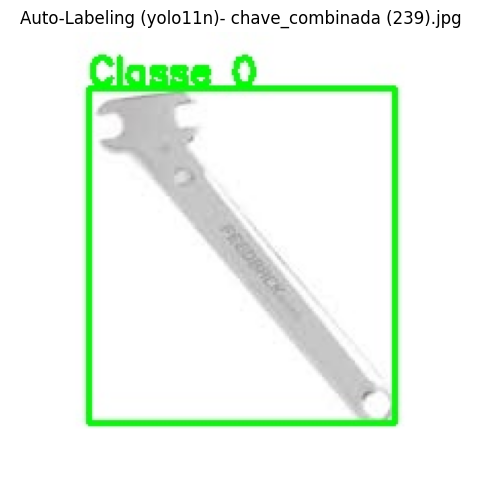

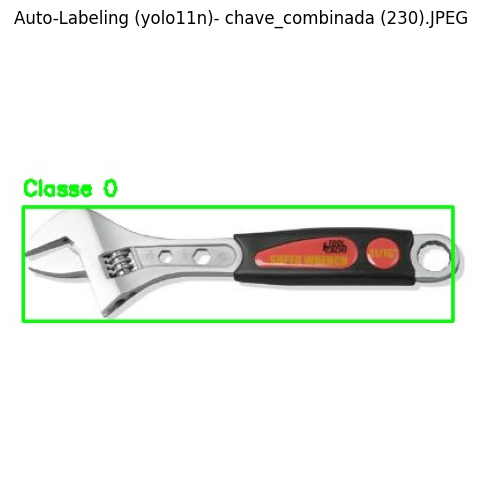

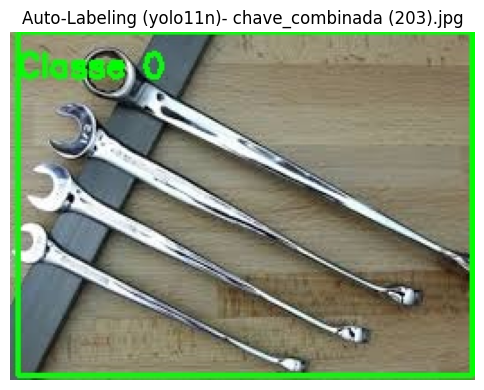

In [ ]:
mf.exibir_resultado_auto_labeling(pasta_processadas="dataset/auto-labeling_inicial", num_amostras=3)

## => As bounding boxes geradas ficaram bem erradas/estranhas, rss.... Isso vai dar trabalho!
Já era de se esperar! Como o YOLO base foi treinado no dataset geral do COCO (que tem coisas como pessoas, carros, cadeiras, garrafas), ele não tem a menor ideia do que é uma chave combinada. Ele tenta adivinhar com base em formas parecidas, o que geralmente resulta em caixas totalmente fora do lugar (ou ele pega um pedaço da bancada, ou ignora a chave).

Ainda bem que percebemos isso agora, antes de treinar o modelo com lixo <font color="orange">**("Garbage in, garbage out")**</font>.

❗ O processo de geração do auto-labeling pela função acima não ficou satisfatório.<br>
Utilizou-se um modelo base, no caso o Yolo11n,  para o `auto-labeling`.<br>
Para documentação, há o registro de alguns resultados acima, e acabamos optando por utilizar a solução da Roboflow (https://app.roboflow.com/), e desenhar as bounding boxes, <font color=mf.g_verde_claro><u>e segmentação por polígonos também</u></font>, que acabou sendo a melhor alternativa.<br>
O processo na sequência, já exibe os resultados após a importação das imagens processadas no Roboflow.

## 🎯 3.0 Utilizando o Roboflow

In [ ]:
%pip install roboflow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 373.9/373.9 kB 10.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 60.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 6.7 MB/s eta 0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.3
    Uninstalling typer-0.27.3:
      Successfully uninstalled typer-0.27.3


## 🔄 3.1 Exportar as imagens de treino e validação do Roboflow para um diretório local

In [ ]:
from roboflow import Roboflow

# Inicializar com a chave de API
rf = Roboflow(api_key="kVAO3w4YX0RTpvX5cA23")

# Conectar-se ao workspace e projeto
workspace = rf.workspace("plimas-workspace") # Nome do workspace no Roboflow
project = workspace.project("vac2")    # Nome do projeto

# Exportar diretamente os dados da seção de imagens sem gerar versão
workspace.search_export(
    query="*",                       # Trazer todas as imagens anotadas
    format="yolov8",                   # Formato desejado (ex: "coco" ou "yolov8")
    dataset="vac2",           # ID do projeto
    location="./dataset_exportado"   # Pasta de destino no computador
)

print(f"{mf.NEGRITO}{mf.VERDE}[SUCESSO] ✓ Dataset exportado sem gastar créditos de versão!{mf.RESET}")

loading Roboflow workspace...
loading Roboflow project...
Export started (id=ZNOzMluvTI). Polling for completion...
If this takes too long, you can check the export status at: https://api.roboflow.com/plimas-workspace/search/export/ZNOzMluvTI?api_key=YOUR_API_KEY


Extracting search export to /content/drive/MyDrive/Colab Notebooks/vision-auto-check/dataset_exportado: 100%|██████████| 294/294 [00:02<00:00, 137.03it/s]

Search export extracted to /content/drive/MyDrive/Colab Notebooks/vision-auto-check/dataset_exportado
[SUCESSO] ✓ Dataset exportado sem gastar créditos de versão!


# 🔎 3.2 Checagem aleatória de 3 **`Bounding boxes/Polígono (Segmentação)`** geradas. Apenas para certificações...

Inicialmente, como as imagens geradas não estavam separadas entre treino e validação, foram armazenadas num diretório específico ("./dataset_exportado") para na sequência serem distribuídas aos diretórios apropriados de treino e validação.

[INFO] Exibindo 3 amostras aleatórias da pasta 'train'


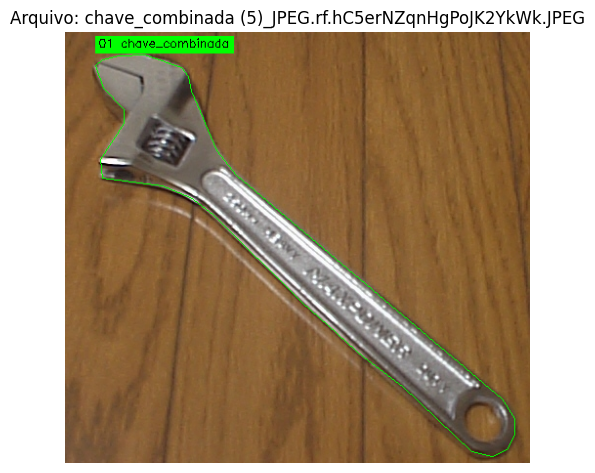

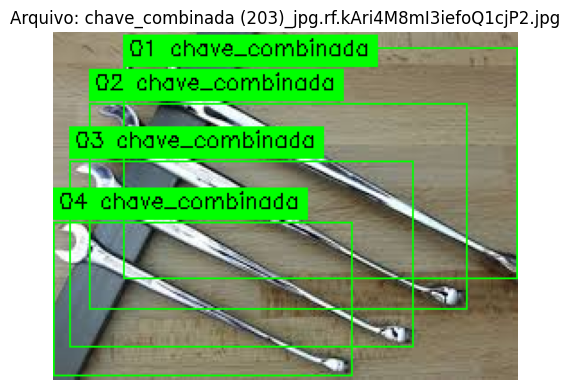

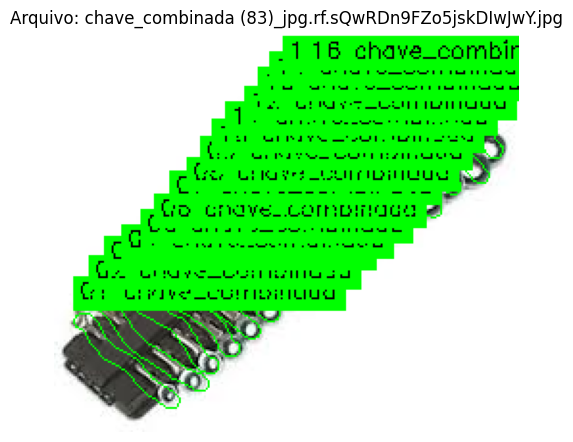

In [ ]:
# Exibe 3 imagens aleatórias com seus respectivos bounding boxes desenhados
mf.visualizar_amostras_labels(pasta_base="dataset", split="train", num_amostras=3, salvar_disco=False)

A abordagem que foi utilizada neste pipeline é a de validar a infraestrutura de ponta a ponta <font color="yellow">(pipeline MVP ou Proof of Concept)</font>.
Validaremos primeiramente toda a estrutura do pipeline com uma única classe e completando o ciclo, voltamos para a contemplação das demais classes.

Por que adotar esta estratégia?
  - Isolamento de Erros: Se algo der errado no treinamento, saberemos que o problema é no código do pipeline (hiperparâmetros, formato de diretórios, GPU, épocas), e não na complexidade de gerenciar múltiplos rótulos ou confusão entre classes.

  - Velocidade de Iteração: Treinar com apenas uma classe (chave_combinada) é muito mais rápido para testar se o modelo converge, se o data.yaml está conversando direito com o Ultralytics e se o Colab não vai cair por falta de memória.

  - Escalabilidade Tranquila: Com o pipeline testado e redondo, adicionar novas classes no futuro é apenas uma questão de atualizar o data.yaml e re-anotar as novas ferramentas. A estrutura do código permanece idêntica. ✔

## 🟢 4.0 Iniciar Treinamento do Modelo

In [ ]:
# Disparar o treinamento oficial do pipeline MVP para 'chave_combinada (inicialmente)'
resultados_treino = mf.treinar_modelo_yolo(
    caminho_yaml="dataset/data.yaml",
    modelo_base="yolo11n.pt",               # YOLOv11 nano (ideal para testes rápidos iniciais)
    epochs=50,                              # Quantidade segura para ver convergência inicial
    patience=15,                            # Limita em 15 caso perceba que o modelo não está evoluindo
    imgsz=640,
    batch=16,
    nome_projeto="vision_auto_check_mix",
    nome_experimento="chave_combinada_v1"
)

[INFO] 🚀 Carregando modelo base: yolo11n.pt...
[INFO] 🎯 Iniciando treinamento para o projeto 'vision_auto_check' (Experimento: chave_combinada_v1)...
[INFO] Configurações: Épocas=50 | Imgsz=640 | Batch=16

Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0

## 🧩 4.1 Análise do Treinamento Realizado

Na geração da saída anterior, percebe-se a menção ao yolo26.
Vamos compreender bem esta referência feita pois o nosso parâmetro para treinamento do modelo foi a escolha do yolo11n.

Olhando com atenção para o log de saída, aconteceu um detalhe importante interno da biblioteca da Ultralytics: Na linha onde a biblioteca roda as verificações de Automatic Mixed Precision (AMP), veja o que ela fez:

  - AMP: <font color=mf.g_verde_claro>downloading yolo26n.pt</font> for AMP checks (one-time, <u>**not used for training**</u>)...

O que aconteceu de verdade?
  - O Modelo de Treino Principal: O modelo principal utiliza o parâmetro (yolo11n.pt) que foi o utilizado para o treinamento (note na arquitetura que o Colab carregou a estrutura de 181 camadas do YOLOv11 e os pesos correspondentes).
    - <font color=mf.g_verde_claro>"**YOLO11n** summary: 181 layers, 2,590,035 parameters, 2,590,019 gradients, 6.5 GFLOPs"</font>
  - O comportamento do AMP: A versão mais recente da biblioteca ultralytics instalada no ambiente faz uma checagem interna de precisão mista antes de começar a treinar e, por padrão, baixa um peso de referência auxiliar (yolo26n.pt) para rodar esse teste de compatibilidade de hardware na GPU Tesla T4.

Ou seja, o treino usou sim o YOLOv11 (yolo11n.pt) conforme definimos, mas a ferramenta em si baixou e mencionou o yolo26n.pt nos bastidores para os testes de checagem do ambiente.

## 4.2 O Inesperado:

Na execução o Colab retornou isso:

  - *"ignoring corrupt image/label: labels mix segment and detection rows<br>
  WARNING ⚠️ Box and segment counts should be equal, but got len(segments) = 113, len(boxes) = 293. To resolve this only boxes will be used..."*<br>
    <font color=mf.g_verde_claro>**“To resolve this only boxes will be used and all segments will be removed.”**</font> (Para resolver isso, apenas as caixas serão usadas e todos os segmentos serão removidos).

Até este momento, realmente não sabia, que não poderia misturar bounding boxes e polígonos de segmentação no mesmo dataset de treinamento do YOLO.

Por que o YOLO não lida bem com a mistura?

A estrutura dos arquivos de texto (.txt) de anotação muda completamente entre os dois mundos:

  1. Detecção (Bounding Box): Cada linha espera exatamente 5 valores: [classe, x_centro, y_centro, largura, altura].

  2. Segmentação (Polígono): Cada linha espera uma sequência longa de coordenadas (pares x, y que contornam o objeto): [classe, x1, y1, x2, y2, x3, y3, ...].

Quando o YOLO vai ler os arquivos de label e encontra uma mistura (um arquivo com 5 números e outro com dezenas de números), ele entra em conflito sobre qual tarefa executar <font color="yellow">(detect ou segment)</font>.

O que o YOLO fez neste treino?

  * Como iniciamos um treino de Detecção **(task=detect)**, o YOLO aplicou uma regra de segurança interna que apareceu no log:

  * Ou seja, <u>ele ignorou e jogou fora os polígonos de segmentação daquelas imagens mistas</u>, o que significa que perdemos parte das anotações originais durante o treinamento daquele lote.

A Boa Prática:

  - Para garantir que o modelo aprenda com 100% dos dados preparados, o dataset <u>precisa ser uniforme</u>:

Se o objetivo atual é Detecção de Objetos (Bounding Box), todas as anotações nos arquivos .txt devem ter exatamente o formato de 5 valores.

Se no futuro optarmos por evoluir para Segmentação de Instâncias (para recortar o formato exato da chave), aí sim você usaremos polígonos e configuraremos o YOLO para <u>task=segment</u>.

Como o foco deste MVP é consolidar o pipeline de detecção com caixas, o ideal para as próximas rodadas é padronizar a exportação no Roboflow para Bounding Box puro, eliminando qualquer resíduo de polígono. Vamos ficar atentos! 📌

Nesta classe inicial (chave_combinada), deixaremos como está até por efeitos didáticos de documentação deste pipeline, porém nas demais classes optaremos por apenas aplicar bounding boxes.

## Sobre task=detect / task=segment

O parâmetro "task" não fica explícito no código fonte. Na verdade, "task=detect" foi uma decisão automática tomada pela própria biblioteca da Ultralytics.

Funciona assim por baixo dos panos:

  1. Quando se passa o arquivo de configuração (data.yaml), o YOLO lê o arquivo e olha o formato das anotações nos arquivos .txt.

  2. Como a grande maioria das anotações eram caixas delimitadoras (5 valores), o YOLO deduz sozinho que a tarefa (task) é detecção de objetos (detect).

  3. É por isso que no log apareceu impresso task=detect (junto com dezenas de outros parâmetros padrão que a biblioteca assume automaticamente quando inicia o model.train()).

Portanto, o YOLO infere a tarefa com base na estrutura dos dados de treino. Se o dataset fosse inteiramente de polígonos, ele mudaria automaticamente para task=segment.

## 4.3 Sobre a interrupção no treinamento para evitar o <font color="#32CD32">**Overfitting**</font>

Assim como no Keras, o treinamento com YOLO possui um mecanismo nativo de Early Stopping que monitora o desempenho do modelo na validação e interrompe o treino caso ele pare de melhorar (ou comece a sofrer overfitting).

O melhor de tudo é que ele <font color="yellow">**já vem ativado por padrão**</font> na biblioteca da Ultralytics!

Se repararmos no log aparece:

  - patience=100

Como funciona o Early Stopping no YOLO?

O parâmetro patience define o número de épocas consecutivas que o modelo vai aguardar sem apresentar melhora na métrica principal de validação (geralmente o mAP50) antes de cancelar o treinamento automaticamente.

Com a paciência configurada para 100, e o treino tinha um total de 50 épocas, ele roda até o final sem parar.

Se estivéssemos treinando por 300 épocas, por exemplo, e por volta da época 150 o modelo estagnasse por 100 épocas seguidas, o próprio YOLO pararia o treino sozinho e preservaria os melhores pesos salvos em best.pt.

<font color="orange">No caso deste pipeline, na função de treinamento definimos um parâmetro com paciência para 15 (patience=15). Será mais rigoroso e encerrará caso fique 15 épocas sem evoluir.</font>

## 4.4 A métrica <font color="yellow">**mAP**</font>:

Métricas Finais (best.pt):

  - mAP50: 0.59 (59%)

  - mAP50-95: 0.361 (36.1%)

Para um primeiro treino de 50 épocas com um modelo nano e um dataset ainda em fase de ajuste de rótulos, obter um mAP50 de quase 60% logo de cara mostra que o modelo já aprendeu a enxergar a chave combinada.

## ⚡ 5.0 Testar o treinamento realizado

```
├── train/
├── val/
└── test/
    └── images/      # Novas imagens para teste
```

[INFO] 🚀 Carregando modelo treinado de: runs/detect/vision_auto_check/chave_combinada_v1-3/weights/best.pt
[INFO] 🔍 Executando inferência em 3 imagens selecionadas aleatoriamente...



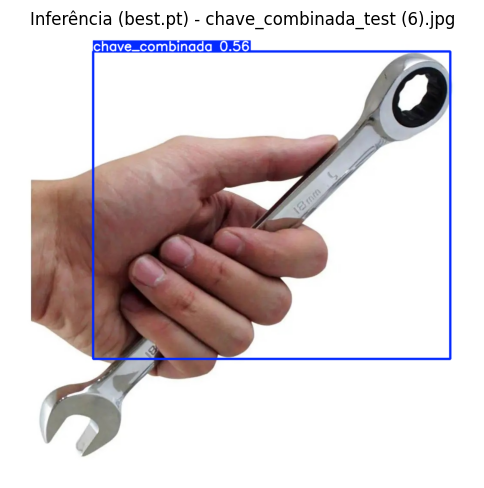

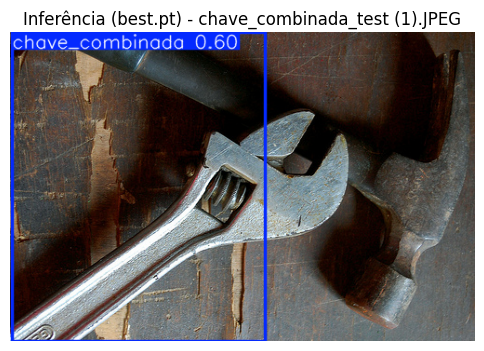

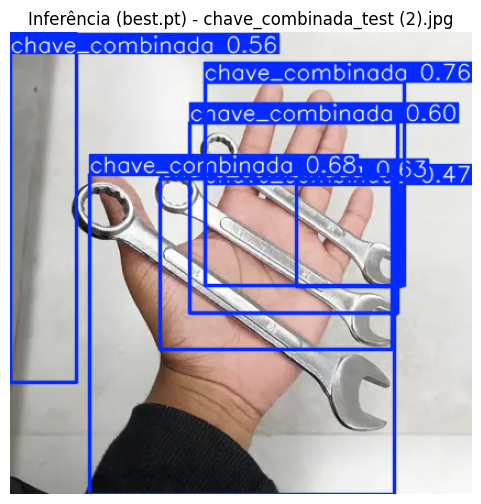

In [ ]:
# Testar o modelo com o best.pt gerado no treino
mf.testar_modelo_yolo(
    caminho_pesos="runs/detect/vision_auto_check/chave_combinada_v1-3/weights/best.pt",   # Confirmar o caminho com o mais recente diretório
    pasta_teste="dataset/test/images",
    num_amostras=3,
    conf_min=0.4      # Limite mínimo de confiança (40%)
)

##

## 📂 6.0 Ajustes - Bounding Boxes

Para não perder o histórico deste pipeline, e o uso de imagens da classe inicial (chave_combinada), com detecção por caixas e segmentação com polígonos, vamos criar um novo dataset.

Este novo dataset será o <font color="yellow">**dataset_bbox**</font>.
Agora ajustado para receber apenas detecções no estilo das bounding boxes.

In [ ]:
# Criação do novo dataset => dataset_bbox
# Executar a separação e limpeza
mf.gerar_dataset_bbox(origem="dataset", destino="dataset_bbox")

[INFO] 🚀 Iniciando a criação do 'dataset_bbox' a partir de 'dataset'...
[INFO] 📄 Arquivo 'data.yaml' copiado com sucesso para a raiz de 'dataset_bbox'.

[INFO] 📁 Processando split com filtragem: [train]...
#ADD8E6  [IGNORADO] chave_combinada (61)_JPEG.rf.G0OIlvdfrLqiIwadEo81.txt contém polígonos (segmentação).
#ADD8E6  [IGNORADO] chave_combinada (198)_JPEG.rf.wBZ8yza919aOzpwvVIbC.txt contém polígonos (segmentação).
#ADD8E6  [IGNORADO] chave_combinada (220)_JPEG.rf.7bUbYpuCa7UvTiT6yv3f.txt contém polígonos (segmentação).
#ADD8E6  [IGNORADO] chave_combinada (227)_JPEG.rf.fFR1qJznc0VDjSMQy4ki.txt contém polígonos (segmentação).
#ADD8E6  [IGNORADO] chave_combinada (217)_JPEG.rf.g5Fcu0c9TpPIYr0mDgnO.txt contém polígonos (segmentação).
#ADD8E6  [IGNORADO] chave_combinada (10)_jpg.rf.9y55E2JAbkX4OhO4fOMD.txt contém polígonos (segmentação).
#ADD8E6  [IGNORADO] chave_combinada (208)_JPEG.rf.rTItNFliicYtvKUWZZRn.txt contém polígonos (segmentação).
#ADD8E6  [IGNORADO] chave_combinada (213)_JPEG.r

Lembrete: Logo após criar o diretório dataset_bbox, ajustar o conteúdo do data.yaml para referenciar este novo diretório.

## 🟢 Próxima etapa, o treinamento em si... (train_bbox.ipynb)

---
FIM